# 제목 유사도에서 풀이 아이디어 재정렬까지
## tl;dr
- 실제 새 임베딩과 Cross-encoder 추론을 수행한 로컬 예비 실험이다.
- 작성·AI 검토된 설명 90개(LeetCode 60, AtCoder 20, Codeforces 10)를 사용한다. 사람 정답 라벨이 아니다.
- 이 노트북은 작은 90개 입력을 **다시 임베딩**하고, 60/90개 후보군의 **실제 Cross-encoder 추론도 다시 실행**한다.
- 큰 본문 실험 9,264개는 기존의 새 실행 영수증을 검증해 읽는다. 기본 실행에서 7분짜리 본문 임베딩을 반복하지 않는다.
- Two Sum → House Robber 같은 어색한 1위 사례가 두 질문 조건에서 재현됐다. **후보 일치율·순위 변화는 정확도나 학습 효과가 아니다.**

실행 환경: 프로젝트 `.venv` Python 커널. 필요한 로컬 가중치와 private-learning 자료는 아래 해시 검증으로 확인한다. 네트워크·유료 API·훈련은 사용하지 않는다.

## Context & Methods
학습 목적은 문제 내용 유사, 풀이 아이디어 연습, 약점 보완으로 나눴다. 이번 노트북은 정적인 내용/아이디어 후보를 비교한다. 학습 기록을 조건으로 한 약점 보완의 효과는 평가하지 않는다.

### Key Assumptions
1. `concept_rationale`와 `concepts`는 출처가 있는 작성 설명이지만 알고리즘 정답/숙련의 증거는 아니다.
2. 세 임베딩 입력은 같은 문제와 같은 MiniLM 모델을 사용한다. Cross-encoder는 두 설명 검색 Top10의 합집합만 재정렬한다.
3. 재정렬의 질문형 조건과 설명 직접 조건은 같은 후보를 사용한다. Cross-encoder는 범용 MS MARCO 모델이며 instruction-following/알고리즘 관계 판정 모델로 학습됐다고 가정하지 않는다.
4. 모델 raw logit은 코사인이나 정답 확률이 아니다. 서로 다른 점수의 크기를 우열로 비교하지 않는다.
5. 원문 페이지/코드 수집은 하지 않는다. publisher 실험에 LeetCode 본문은 없고 AtCoder의 미확인 ID는 그대로 둔다.

### 1. 환경과 경로

In [1]:
from pathlib import Path
import contextlib, gc, io, json, os, platform, sys, time
os.environ.update(HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'research/recommendation_inputs').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown, Image as NotebookImage
from research.recommendation_inputs.compare import digest, verify, compare_rankings
from research.recommendation_inputs.experiments import backend, encode_chunks
from research.recommendation_inputs.cross_encoder import load_local, rerank_bundle
HERE = ROOT/'research/recommendation_inputs'
PRIVATE = ROOT/'private-learning/recommendation-inputs'
FIG = HERE/'figures'
FIG.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 85)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11, 'figure.facecolor':'#fafaf7', 'axes.facecolor':'#fafaf7', 'axes.spines.top':False, 'axes.spines.right':False, 'axes.labelcolor':'#28382e', 'text.color':'#28382e', 'savefig.dpi':160})
GREEN='#365d47'; GREY='#a6b2a6'
display(pd.DataFrame([{'Python':platform.python_version(), 'Architecture':platform.machine(), 'NumPy':np.__version__, 'Device':'CPU', 'Network':'offline'}]))

Matplotlib is building the font cache; this may take a moment.


,Python,Architecture,NumPy,Device,Network
0,3.13.2,arm64,2.1.3,CPU,offline


## Data
### 2. 출처와 저장된 결과 검증
public 영수증과 private manifest가 일치하고, scope 파일 해시가 같을 때만 읽는다. 원문 텍스트를 공개 출력하지 않는다. 모델 폴더는 loader에서 정확한 파일 구성과 해시를 검사한다.

In [2]:
def load_run(folder, receipt_file):
    root=PRIVATE/folder
    receipt=json.loads((HERE/receipt_file).read_text())
    assert json.loads((root/'manifest.json').read_text())==receipt
    bundles={}
    for scope,info in receipt['scopes'].items():
        path=root/info['file'];verify(path,info['sha256'])
        bundles[scope]=json.loads(path.read_text())
    return receipt,bundles
ideas, idea_bundles=load_run('curriculum-ideas-v1','curriculum-ideas-v1.receipt.json')
question_receipt, question_bundles=load_run('curriculum-rerank-v1','curriculum-rerank-v1.receipt.json')
plain_receipt, plain_bundles=load_run('curriculum-rerank-plain-v1','curriculum-rerank-plain-v1.receipt.json')
publisher=json.loads((HERE/'publisher-structure-v1.receipt.json').read_text())
assert json.loads((PRIVATE/'publisher-structure-v1/manifest.json').read_text())==publisher
for name,expected in publisher['files_sha256'].items():verify(PRIVATE/'publisher-structure-v1'/name,expected)
display(pd.DataFrame([
 {'Cohort':'Authored ideas / all','Problems':90,'Platforms':'60 LC / 20 AtCoder / 10 CF','Evidence':'AI-drafted and AI-reviewed annotations'},
 {'Cohort':'Authored ideas / LeetCode','Problems':60,'Platforms':'LeetCode only','Evidence':'Subset of the same annotations'},
 {'Cohort':'Parsed publisher text','Problems':publisher['matched_count'],'Platforms':str(publisher['counts']),'Evidence':'Admitted descriptions; no LC text'}
]))

,Cohort,Problems,Platforms,Evidence
0,Authored ideas / all,90,60 LC / 20 AtCoder / 10 CF,AI-drafted and AI-reviewed annotations
1,Authored ideas / LeetCode,60,LeetCode only,Subset of the same annotations
2,Parsed publisher text,9264,"{'atcoder': 1275, 'codeforces': 7989}",Admitted descriptions; no LC text


### 3. 실제 입력 확인

In [3]:
source='leetcode:two-sum'
problem=idea_bundles['strategy_leetcode']['problems'][source]
display(pd.DataFrame([{'Input':name,'Exact text':problem['input_views'][name]} for name in ['title','idea_rationale','idea_structured']]))
display(Markdown('출처: **'+problem['input_provenance']+'**. 미기록 필드: '+', '.join(problem['input_views']['missing_strategy_fields'])))

,Input,Exact text
0,title,Two Sum
1,idea_rationale,Stores prior values so each complement is checked once.
2,idea_structured,CORE IDEA\nStores prior values so each complement is checked once.\n\nCONCEPTS\nh...


출처: **Luna draft; independent Sol review per user authorization; not human empirical gold**. 미기록 필드: explicit state/invariant, correctness argument, complexity analysis

## Results
### 4. 90개 작성 입력을 다시 임베딩
동일한 고정 MiniLM과 원래-token chunk pooling으로 세 입력을 다시 계산한다. 원래 저장 벡터와의 오차를 확인하되, 모델/문제의 정답성을 검증한 것으로 해석하지 않는다. 본문 9,264개의 재실행 명령은 마지막에 있다.

In [4]:
minilm=backend()
all_problems=idea_bundles['strategy_all']['problems']
all_keys=list(all_problems)
reencoded={}; encoding_rows=[]
for name in ['title','idea_rationale','idea_structured']:
    values=[all_problems[key]['input_views'][name] for key in all_keys]
    with contextlib.redirect_stdout(io.StringIO()):vectors,stats=encode_chunks(values,minilm)
    old=np.load(PRIVATE/'curriculum-ideas-v1'/f'{name}.npy',allow_pickle=False)
    error=float(np.max(np.abs(vectors-old)))
    assert error<1e-5 and np.isfinite(vectors).all()
    assert np.allclose(np.linalg.norm(vectors,axis=1),1,atol=1e-5)
    reencoded[name]=vectors
    encoding_rows.append({'Input':name,'Problems':len(values),'Chunks':stats['chunks'],'Encode seconds':stats['encode_seconds'],'Maximum abs difference':error})
display(pd.DataFrame(encoding_rows))
del minilm;_ = gc.collect()

/Users/jeonghun/Algorithm-RAG-Engine/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


,Input,Problems,Chunks,Encode seconds,Maximum abs difference
0,title,90,90,0.104306,0.0
1,idea_rationale,90,90,0.099533,0.0
2,idea_structured,90,90,0.158904,0.0


### 5. 같은 후보에 실제 Cross-encoder 재추론
질문형: `Which problem uses the same core solving idea as this? {핵심 설명}`.
설명 직접: `{핵심 설명}`.
후보 passage는 항상 구조화 설명이다. 조용한 입력 잘림을 허용하지 않으며, 두 조건의 후보 수가 같아야 한다.

In [5]:
import torch
MODEL=ROOT/'private-learning/models/ms-marco-MiniLM-L6-v2-233902d'
MODEL_MANIFEST=ROOT/'private-learning/models/ms-marco-MiniLM-L6-v2-233902d.manifest.json'
model,model_info=load_local(MODEL,MODEL_MANIFEST)
display(pd.DataFrame([{'Model':model_info['model_id'],'Revision':model_info['revision'],'Downloaded MB':model_info['total_bytes']/1e6,'Weights SHA256':model_info['weights_sha256']}]))
rerun={}; timing_rows=[]
for query_mode in ['instruction','plain']:
    for source_scope in ['strategy_leetcode','strategy_all']:
        bundle=idea_bundles[source_scope]
        token_check={}
        def score_pairs(pairs):
            lengths=[len(model.tokenizer.encode(a,b,add_special_tokens=True,truncation=False)) for a,b in pairs]
            token_check['max_pair_tokens']=max(lengths)
            assert max(lengths)<=512
            return model.predict(pairs,batch_size=32,show_progress_bar=False,activation_fn=torch.nn.Identity(),convert_to_numpy=True).reshape(-1).tolist()
        start=time.perf_counter()
        rankings,stats=rerank_bundle(bundle,score_pairs,query_mode=query_mode)
        seconds=time.perf_counter()-start
        saved_scope=('rerank_' if query_mode=='instruction' else 'rerank_plain_')+('leetcode' if source_scope=='strategy_leetcode' else 'all')
        frozen=(question_bundles if query_mode=='instruction' else plain_bundles)[saved_scope]['rankings']['cross_encoder']
        max_error=0.
        for query,values in rankings.items():
            assert [p[0] for p in values]==[p[0] for p in frozen[query]]
            max_error=max(max_error,max(abs(a[1]-b[1]) for a,b in zip(values,frozen[query])))
        assert max_error<1e-5
        rerun[(query_mode,source_scope)]=rankings
        timing_rows.append({'Query mode':query_mode,'Cohort':source_scope,'Queries':stats['query_count'],'Pairs':stats['pair_count'],'Scoring seconds':seconds,'Pairs per second':stats['pair_count']/seconds,'Max pair tokens':token_check['max_pair_tokens'],'Max saved logit difference':max_error})
timing=pd.DataFrame(timing_rows)
assert timing.groupby('Cohort')['Pairs'].nunique().eq(1).all()
display(timing.round(4))

,Model,Revision,Downloaded MB,Weights SHA256
0,cross-encoder/ms-marco-MiniLM-L6-v2,233902d25c440f23af6f7d6e94d2946bac0bee0a,91.819431,821d1aa69520101d6e0737f78a042ae25b19e5cb9160701909d10434f4aeb0ae


,Query mode,Cohort,Queries,Pairs,Scoring seconds,Pairs per second,Max pair tokens,Max saved logit difference
0,instruction,strategy_leetcode,60,874,3.0665,285.0182,58,0.0
1,instruction,strategy_all,90,1340,4.6140,290.4199,58,0.0
2,plain,strategy_leetcode,60,874,2.4399,358.2067,47,0.0
3,plain,strategy_all,90,1340,3.7042,361.7534,47,0.0


### 6. 후보 일치와 순위 변화
Top10 공통 비율은 후보가 얼마나 달라졌는지를 나타낸다. **정확도·재현율·학습 효과가 아니다.** 동일한 60개 LeetCode 문제에서만 아래 방법을 비교한다.

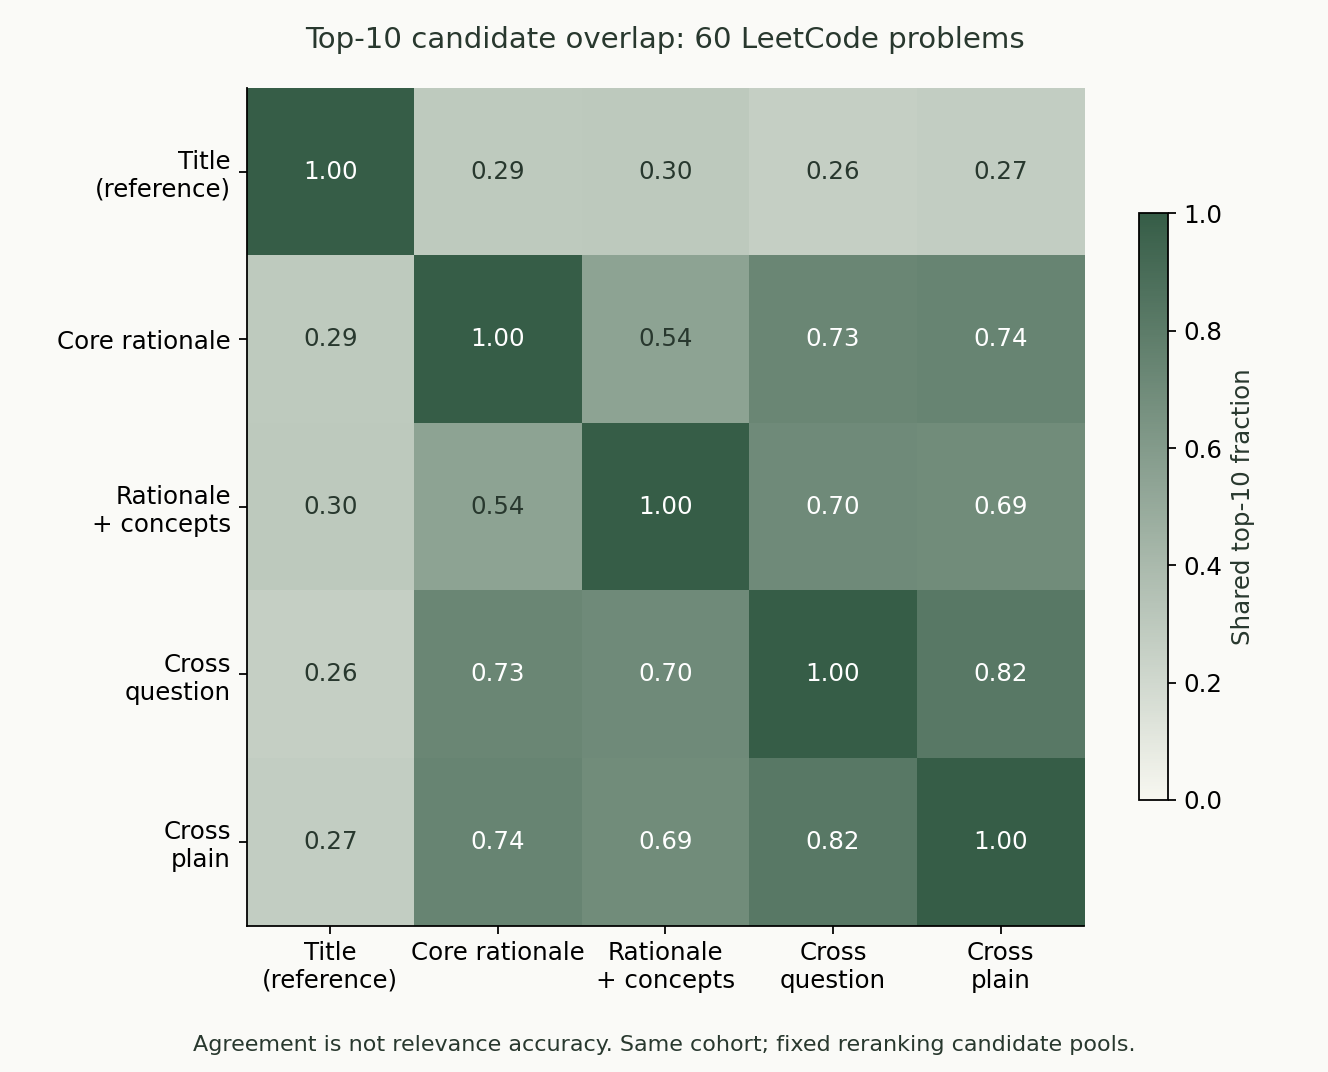

In [6]:
lc=idea_bundles['strategy_leetcode']
combined={name:lc['rankings'][name] for name in ['title','idea_rationale','idea_structured']}
combined['cross_question']=rerun[('instruction','strategy_leetcode')]
combined['cross_plain']=rerun[('plain','strategy_leetcode')]
run_keys={name:{q:[target for target,score in values] for q,values in rows.items()} for name,rows in combined.items()}
diagnostics=compare_rankings(run_keys)
names=list(run_keys)
matrix=np.eye(len(names))
for pair in diagnostics['pairwise']:
    a,b=names.index(pair['a']),names.index(pair['b'])
    matrix[a,b]=matrix[b,a]=pair['top10_overlap_fraction']
labels=['Title\n(reference)','Core rationale','Rationale\n+ concepts','Cross\nquestion','Cross\nplain']
fig,ax=plt.subplots(figsize=(8.3,6.7))
cmap=LinearSegmentedColormap.from_list('warm_green',['#f7f7f0',GREEN])
im=ax.imshow(matrix,vmin=0,vmax=1,cmap=cmap)
ax.set_xticks(range(len(names)),labels);ax.set_yticks(range(len(names)),labels)
for i in range(len(names)):
    for j in range(len(names)):ax.text(j,i,f'{matrix[i,j]:.2f}',ha='center',va='center',color='white' if matrix[i,j]>.6 else '#28382e')
ax.set_title('Top-10 candidate overlap: 60 LeetCode problems',pad=18)
fig.colorbar(im,ax=ax,shrink=.7,label='Shared top-10 fraction')
fig.text(.5,.02,'Agreement is not relevance accuracy. Same cohort; fixed reranking candidate pools.',ha='center',fontsize=10)
fig.tight_layout(rect=(0,.05,1,1));fig.savefig(FIG/'leetcode-candidate-overlap.png');fig.savefig(FIG/'leetcode-candidate-overlap.svg');display(NotebookImage(filename=str(FIG/'leetcode-candidate-overlap.png')));plt.close(fig)

### 7. 어느 문제로 바뀌었는지 확인

In [7]:
case_rows=[]
for query in ['leetcode:two-sum','leetcode:valid-anagram','leetcode:binary-search']:
    for method in ['idea_structured','cross_question','cross_plain']:
        candidate,score=combined[method][query][0]
        case_rows.append({'Source':lc['problems'][query]['title'],'Method':method,'Top candidate':lc['problems'][candidate]['title'],
                          'Candidate core rationale':lc['problems'][candidate]['input_views']['idea_rationale'],
                          'Score kind':'cosine' if method=='idea_structured' else 'raw logit', 'Recorded score':score})
cases=pd.DataFrame(case_rows)
display(cases.round({'Recorded score':4}))
assert cases[(cases.Source=='Two Sum')&cases.Method.isin(['cross_question','cross_plain'])]['Top candidate'].eq('House Robber').all()

,Source,Method,Top candidate,Candidate core rationale,Score kind,Recorded score
0,Two Sum,idea_structured,Contains Duplicate,Tests whether a set captures the only state needed for duplicate detection.,cosine,0.6565
1,Two Sum,cross_question,House Robber,Each index compares skipping it with taking it after the prior-prior state.,raw logit,-0.0905
2,Two Sum,cross_plain,House Robber,Each index compares skipping it with taking it after the prior-prior state.,raw logit,-9.5437
3,Valid Anagram,idea_structured,Top K Frequent Elements,Separates counting from selection of the largest frequencies.,cosine,0.5840
4,Valid Anagram,cross_question,Valid Palindrome,Compares normalized alphanumeric characters from opposite ends.,raw logit,0.9158
5,Valid Anagram,cross_plain,Valid Palindrome,Compares normalized alphanumeric characters from opposite ends.,raw logit,-5.8421
6,Binary Search,idea_structured,Search in Rotated Sorted Array,Uses the sorted half to decide which interval can contain the target.,cosine,0.8396
7,Binary Search,cross_question,Search in Rotated Sorted Array,Uses the sorted half to decide which interval can contain the target.,raw logit,3.1818
8,Binary Search,cross_plain,Search in Rotated Sorted Array,Uses the sorted half to decide which interval can contain the target.,raw logit,-5.1269


Two Sum에서 두 Cross-encoder 조건 모두 House Robber를 1위에 놓았다. 이는 이번 입력/질문 템플릿/후보군에서의 재현 가능한 실패 관찰이다. 모든 Cross-encoder가 실패한다거나 다른 모델보다 정확도가 낮다는 일반 결론은 아니다. 범용 passage relevance가 알고리즘 관계의 정의와 자동으로 일치하지 않는다는 점을 점검할 사례다.

### 8. 추론 비용 확인

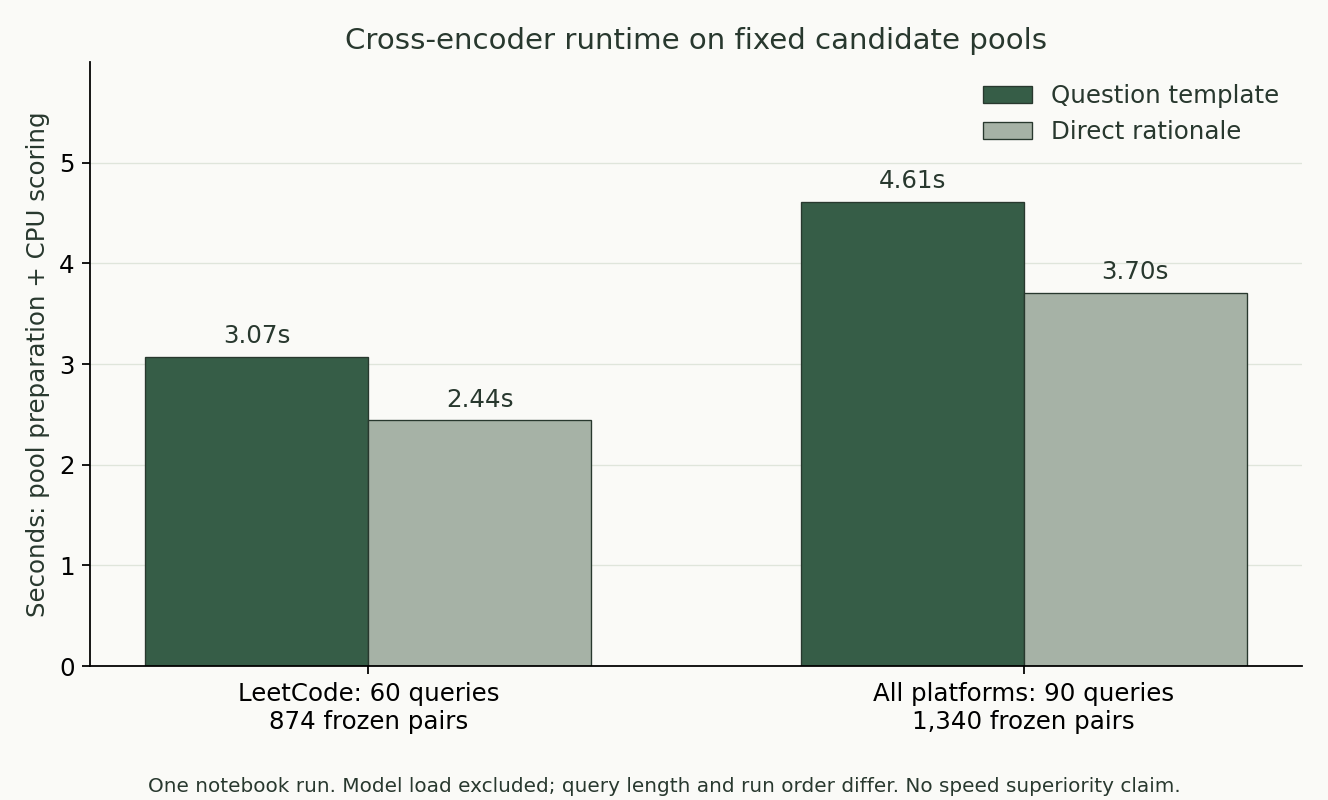

In [8]:
fig,ax=plt.subplots(figsize=(8.3,5))
scopes=['strategy_leetcode','strategy_all'];x=np.arange(2);width=.34
for offset,mode,color in [(-width/2,'instruction',GREEN),(width/2,'plain',GREY)]:
    rows=timing[timing['Query mode']==mode].set_index('Cohort').loc[scopes]
    bars=ax.bar(x+offset,rows['Scoring seconds'],width,label='Question template' if mode=='instruction' else 'Direct rationale',color=color,edgecolor='#28382e',linewidth=.6)
    ax.bar_label(bars,labels=[f'{v:.2f}s' for v in rows['Scoring seconds']],padding=4)
ax.set_xticks(x,['LeetCode: 60 queries\n874 frozen pairs','All platforms: 90 queries\n1,340 frozen pairs'])
ax.set_ylim(0,timing['Scoring seconds'].max()*1.3);ax.set_ylabel('Seconds: pool preparation + CPU scoring')
ax.set_title('Cross-encoder runtime on fixed candidate pools');ax.legend(frameon=False)
ax.yaxis.grid(True,color='#dfe5db',linewidth=.6);ax.set_axisbelow(True)
fig.text(.5,.01,'One notebook run. Model load excluded; query length and run order differ. No speed superiority claim.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.05,1,1));fig.savefig(FIG/'cross-encoder-runtime.png');fig.savefig(FIG/'cross-encoder-runtime.svg');display(NotebookImage(filename=str(FIG/'cross-encoder-runtime.png')));plt.close(fig)

### 9. 큰 본문 실험의 기록 확인
아래 표는 현재 노트북에서 9천 개 입력을 다시 임베딩한 시간이 아니라 **앞서 실제 실행한 영수증**이다. 문제 원문은 출력하지 않는다. 같은 9,264개 query/candidate 코호트에서만 비교한다.

In [9]:
body_pairs=pd.DataFrame(publisher['diagnostics']['pairwise'])
display(body_pairs[['a','b','queries','mean_shared_top10','top1_agreement_fraction']].round(4))
display(pd.DataFrame([{'Input':name,**values} for name,values in publisher['timings'].items()]))
assert publisher['matched_count']==sum(publisher['counts'].values())
assert publisher['quality_status'].startswith('unavailable')
print('Publisher full run seconds:',round(publisher['run_seconds'],2))
print('Matched rows:',publisher['matched_count'],'; original rows:',publisher['source_count'])
print('No independently judged precision/nDCG is available.')

,a,b,queries,mean_shared_top10,top1_agreement_fraction
0,task_sections,full_statement,9264,6.7274,0.5253
1,task_sections,io_constraints,9264,2.8606,0.1540
2,task_sections,title,9264,0.6750,0.0257
3,full_statement,io_constraints,9264,2.8546,0.1577
4,full_statement,title,9264,0.6646,0.0283
5,io_constraints,title,9264,0.4374,0.0196


,Input,reused_existing_vectors,encode_seconds,chunks,selected_tokens,all_selected_tokens_covered
0,title,True,NaN,NaN,NaN,NaN
1,full_statement,True,NaN,NaN,NaN,NaN
2,task_sections,NaN,269.409906,17748.0,3351271.0,True
3,io_constraints,NaN,146.145358,9935.0,1304763.0,True


Publisher full run seconds: 426.39
Matched rows: 9264 ; original rows: 9424
No independently judged precision/nDCG is available.


## Takeaways
1. 입력 표현과 재정렬 모델을 바꾸면 후보 순위가 달라진다. 같은 후보를 만든다고 학습 목적에 더 맞는 것은 아니다.
2. 범용 Cross-encoder의 결과에도 명확히 점검할 실패 사례가 남는다. 모델 출력값을 검증된 알고리즘 유사도/확률로 부르지 않는다.
3. 본문 구조, 핵심 풀이 기법, 학습 적합성은 평가 라벨을 따로 준비해야 한다. 복습 표시나 완료 기록만으로 숙련을 확정하지 않는다.
4. 주간 문제 관계 계산과 일간 학습 정책은 후보의 출처·모델·표현을 유지한 채 연결해야 한다. 이번 결과로 운영 추천 순위를 승격하지 않았다.

### 실행 범위
이 노트북은 90개 임베딩 재생성과 두 질문 조건의 실제 CPU 추론을 다시 수행했다. 큰 본문 실험은 해시가 고정된 실행 결과를 사용했다. 사람이 판단한 아이디어/내용/학습 적합성 라벨은 아직 없다.

In [10]:
notebook_receipt={'scope':'notebook fresh curriculum embedding and Cross-encoder rerun','model_manifest_sha256':digest(MODEL_MANIFEST),
                  'input_receipts':{name:digest(HERE/name) for name in ['curriculum-ideas-v1.receipt.json','curriculum-rerank-v1.receipt.json','curriculum-rerank-plain-v1.receipt.json','publisher-structure-v1.receipt.json']},
                  'fresh_encoding':encoding_rows,'fresh_reranking':timing.to_dict(orient='records'),
                  'all_saved_candidate_orders_reproduced':True,'human_quality_evaluation':False,'new_training':False,'paid_api_calls':0}
(HERE/'notebook-last-run.json').write_text(json.dumps(notebook_receipt,ensure_ascii=False,indent=2)+chr(10))
print('All source/model hashes checked; fresh outputs reproduced saved candidate orders.')

All source/model hashes checked; fresh outputs reproduced saved candidate orders.


### 재현 자료와 참고
- 코드: `inputs.py`, `experiments.py`, `cross_encoder.py`, `run_reranker.py`.
- 영수증: `curriculum-ideas-v1.receipt.json`, `publisher-structure-v1.receipt.json`, 두 `curriculum-rerank*.receipt.json`.
- [고정 MiniLM 모델 설명](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/blob/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/README.md)
- [Cross-encoder 모델 설명](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2)
- [Retrieve & Re-rank](https://sbert.net/examples/sentence_transformer/applications/retrieve_rerank/README.html)

큰 본문 입력을 다시 생성하려면 저장소 루트에서 아래 명령을 새 출력 경로로 실행한다. 기존 실행은 덮어쓰지 않는다.

```sh
VECLIB_MAXIMUM_THREADS=1 OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 \
.venv/bin/python -m research.recommendation_inputs.experiments --kind publisher \
  --output private-learning/recommendation-inputs/publisher-structure-v2 \
  --receipt research/recommendation_inputs/publisher-structure-v2.receipt.json
```